<a href="https://colab.research.google.com/github/NEU0127/ZSUProjekt/blob/main/ZSUProjektPart1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projekt ZSU: Analýza olympijských sportovců

Tento Jupyter Notebook obsahuje průzkumnou analýzu, preprocessing dat a clusterovou analýzu na datasetu olympijských sportovců.

* **použitý dataset:** Olympijští sportovci (https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results)

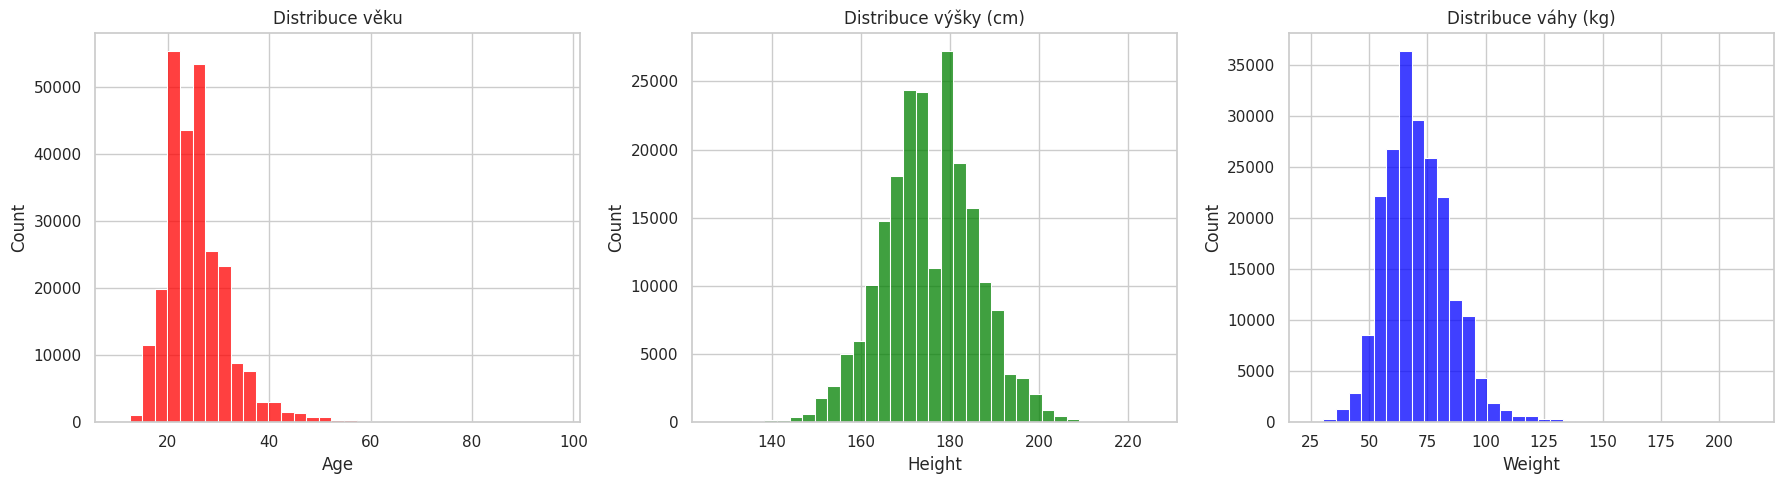

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

df_olympics = pd.read_csv('athlete_events.csv')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data=df_olympics, x='Age', bins=35, ax=axes[0], color='red')
axes[0].set_title('Distribuce věku')
sns.histplot(data=df_olympics, x='Height', bins=35, ax=axes[1], color='green')
axes[1].set_title('Distribuce výšky (cm)')
sns.histplot(data=df_olympics, x='Weight', bins=35, ax=axes[2], color='blue')
axes[2].set_title('Distribuce váhy (kg)')
plt.tight_layout()
plt.show()

### Interpretace univariantní analýzy
* **Věk (Age):** Distribuce věku je nejhustší u hodnot mezi 20. a 30. rokem věku. Jsou zde však i sportovci výrazně starší.
* **Výška (Height):** Distribuce výšky připomíná obvyklou distribuci výšky v obecné populaci, pouze je zde o něco větší množství výrazně vyšších sportovců.
* **Váha (Weight):** Distribuce váhy je o něco překvapivější, ale stále je velice podobná běžné populaci.

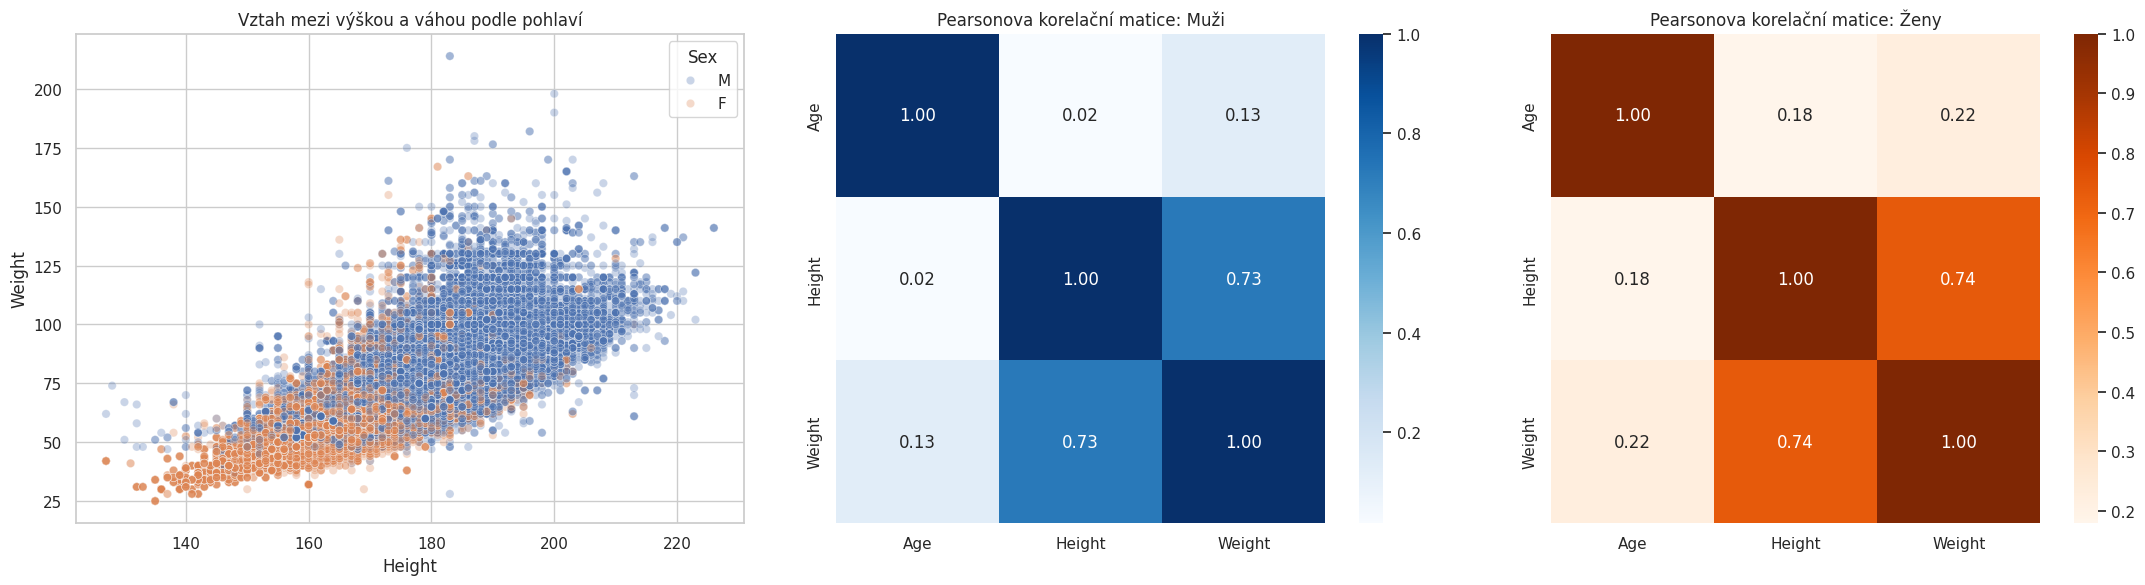

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
sns.scatterplot(data=df_olympics, x='Height', y='Weight', hue='Sex', alpha=0.3, ax=axes[0])
axes[0].set_title('Vztah mezi výškou a váhou podle pohlaví')


numeric_cols = ['Age', 'Height', 'Weight']
mat_male = df_olympics[df_olympics['Sex'] == 'M'][numeric_cols].corr(method='pearson')
mat_female = df_olympics[df_olympics['Sex'] == 'F'][numeric_cols].corr(method='pearson')


sns.heatmap(mat_male, annot=True, fmt=".2f", cmap="Blues", square=True, ax=axes[1])
axes[1].set_title('Pearsonova korelační matice: Muži')


sns.heatmap(mat_female, annot=True, fmt=".2f", cmap="Oranges", square=True, ax=axes[2])
axes[2].set_title('Pearsonova korelační matice: Ženy')

plt.tight_layout()
plt.show()

### Interpretace bivariantní analýzy a korelací
* **Výška vs. Váha:** Scatter Plot ukazuje jasnou závislost mezi pohlavím a výškou/váhou, přesně jak bychom předpokládali.

* **Korelační matice:** Překvapivým zjištěním je, že zatímco u mužů vidíme silnou korelaci pouze mezi výškou a váhou, u žen se objevuje i relativně vyšší korelace věku s oběma tělesnými proporcemi. Tento jev je pravděpodobně způsoben historickým složením ženských olympijských disciplín, kde na jedné straně stojí extrémně mladé a drobné sportovkyně (např. gymnastky a krasobruslařky)

In [ ]:
missing_values = df_olympics[['Age', 'Height', 'Weight']].isna().sum()

print("Absolutní počet chybějících hodnot:")
print(missing_values)

missing_pct = (missing_values / len(df_olympics) * 100).round(2)
print("\nProcentuální podíl chybějících hodnot:")
print(missing_pct.astype(str) + " %")

Absolutní počet chybějících hodnot:
Age        9474
Height    60171
Weight    62875
dtype: int64

Procentuální podíl chybějících hodnot:
Age        3.49 %
Height    22.19 %
Weight    23.19 %
dtype: object


In [ ]:
df_olympics['Height'] = df_olympics.groupby(['Sport', 'Sex'])['Height'].transform(lambda x: x.fillna(x.median()))
df_olympics['Weight'] = df_olympics.groupby(['Sport', 'Sex'])['Weight'].transform(lambda x: x.fillna(x.median()))

df_olympics['Height'] = df_olympics['Height'].fillna(df_olympics['Height'].median())
df_olympics['Weight'] = df_olympics['Weight'].fillna(df_olympics['Weight'].median())

df_olympics['Medal'] = df_olympics['Medal'].fillna('None')

df_olympics['BMI'] = df_olympics['Weight'] / ((df_olympics['Height'] / 100) ** 2)
df_olympics['Medal_Won'] = df_olympics['Medal'].apply(lambda x: 0 if x == 'None' else 1)

print("Ukázka datasetu")
display(df_olympics[['Name', 'Sex', 'Sport', 'Height', 'Weight', 'BMI', 'Medal_Won']].head())

Ukázka datasetu


,Name,Sex,Sport,Height,Weight,BMI,Medal_Won
0,A Dijiang,M,Basketball,180.0,80.0,24.691358,0
1,A Lamusi,M,Judo,170.0,60.0,20.761246,0
2,Gunnar Nielsen Aaby,M,Football,178.0,73.0,23.040020,0
3,Edgar Lindenau Aabye,M,Tug-Of-War,182.0,95.0,28.680111,1
4,Christine Jacoba Aaftink,F,Speed Skating,185.0,82.0,23.959094,0


### Odůvodnění čištění dat a tvorby nových proměnných
* **Chybějící hodnoty:** Chybějící data o hmotnosti a výšce sportovců jsem se rozhodl nahradit mediánem pro dané pohlaví a daný sport, jelikož věřím, že takto bude interpretace nejpřesnější.
* **nové proměnné**
  vytvořil jsem nové proměnné pro BMI jednoduchým výpočtem a získané medaile

In [ ]:
numeric_cols = ['Age', 'Height', 'Weight']
Q1 = df_olympics[numeric_cols].quantile(0.25)
Q3 = df_olympics[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = ((df_olympics[numeric_cols] < (Q1 - 1.5 * IQR)) | (df_olympics[numeric_cols] > (Q3 + 1.5 * IQR))).sum()

print("Počet odlehlých hodnot pro jednotlivé proměnné:")
print(outliers)

Počet odlehlých hodnot pro jednotlivé proměnné:
Age       10317
Height     3024
Weight     5357
dtype: int64


### Outliers
vidíme, že odlehlých hodnot je překvapivě nízké množství, z tohoto důvodu jsem se rozhodl si tyto odlehlé hodnoty ponechat, protože znamenají často korektní reprezentaci jednotlivých konkrétních sportů. Dále mne zaujalo, že je výrazně menší množství odlehlých hmotností než výšek.

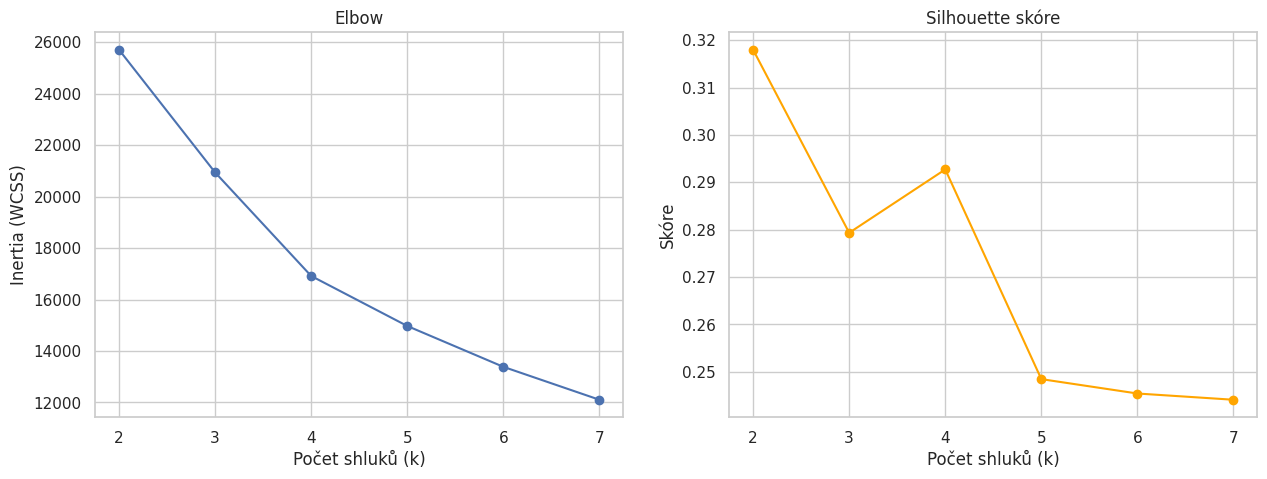

In [ ]:
cluster_features = ['Age', 'Height', 'Weight', 'BMI']
X = df_olympics[cluster_features].dropna().copy()

X_sample = X.sample(n=10000, random_state=42)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

inertia = []
sil_scores = []
k_range = range(2, 8)

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(k_range, inertia, marker='o')
axes[0].set_title('Elbow')
axes[0].set_xlabel('Počet shluků (k)')
axes[0].set_ylabel('Inertia (WCSS)')

axes[1].plot(k_range, sil_scores, marker='o', color='orange')
axes[1].set_title('Silhouette skóre')
axes[1].set_xlabel('Počet shluků (k)')
axes[1].set_ylabel('Skóre')
plt.show()

### množství shluků
Kombinace elbow a silhoutte skore nám ukazuje, že maximální možný počet shluků, který vypadá smysluplně je 4, rozhodl jsem se tedy pro clusterování s počtem shluků 2,3,4 a z těchto výsledků pak zvolit, jaké množství clusterů je nejreprezentativnější.

In [ ]:
k_values = [2, 3, 4]
if 'Medal_Won' not in X_sample.columns:
    X_sample['Medal_Won'] = df_olympics.loc[X_sample.index, 'Medal_Won']

for k in k_values:
    print(f"\n--- Profily shluků pro k = {k} ---")

    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    col_name = f'Cluster_k{k}'
    X_sample[col_name] = kmeans.fit_predict(X_scaled)


    cluster_profiles = X_sample.groupby(col_name)[cluster_features].mean().round(2)


    cluster_profiles['Count'] = X_sample[col_name].value_counts()


    cluster_profiles['Medal_Chance (%)'] = (X_sample.groupby(col_name)['Medal_Won'].mean() * 100).round(2)

    display(cluster_profiles)


--- Profily shluků pro k = 2 ---


,Age,Height,Weight,BMI,Count,Medal_Chance (%)
Cluster_k2,,,,,,
0,23.73,168.67,60.54,21.24,4938,12.03
1,27.29,182.07,81.06,24.44,5062,17.21



--- Profily shluků pro k = 3 ---


,Age,Height,Weight,BMI,Count,Medal_Chance (%)
Cluster_k3,,,,,,
0,24.27,180.29,74.70,22.99,4478,14.76
1,23.89,166.18,58.05,21.00,3754,12.07
2,32.24,182.90,88.68,26.47,1768,19.85



--- Profily shluků pro k = 4 ---


,Age,Height,Weight,BMI,Count,Medal_Chance (%)
Cluster_k4,,,,,,
0,26.33,187.02,92.88,26.61,1563,20.79
1,23.18,165.71,57.35,20.87,3349,11.94
2,38.57,174.71,72.62,23.78,1016,16.93
3,23.91,179.21,73.24,22.83,4072,13.95


In [47]:
cluster_features = ['Age', 'Height', 'Weight', 'BMI']
X_full = df_olympics[cluster_features].dropna().copy()

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_full)

X_full['Medal_Won'] = df_olympics.loc[X_full.index, 'Medal_Won']
X_full['Sex'] = df_olympics.loc[X_full.index, 'Sex']

k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
X_full['Cluster_k4'] = kmeans.fit_predict(X_scaled)

cluster_profiles = X_full.groupby('Cluster_k4')[cluster_features].mean().round(2)
cluster_profiles['Count'] = X_full['Cluster_k4'].value_counts()
cluster_profiles['Medal_Chance (%)'] = (X_full.groupby('Cluster_k4')['Medal_Won'].mean() * 100).round(2)

print("--- Finální profily shluků pro k=4 (Celý dataset: Muži i Ženy) ---")
display(cluster_profiles)

gender_dist = pd.crosstab(X_full['Cluster_k4'], X_full['Sex'], normalize='index') * 100
gender_dist = gender_dist.round(1).astype(str) + ' %'
print("\n--- Procentuální zastoupení pohlaví uvnitř shluků ---")
display(gender_dist)

--- Finální profily shluků pro k=4 (Celý dataset: Muži i Ženy) ---


,Age,Height,Weight,BMI,Count,Medal_Chance (%)
Cluster_k4,,,,,,
0,38.20,175.04,72.76,23.74,28217,14.81
1,26.20,186.83,92.44,26.56,40549,21.37
2,23.95,179.22,73.37,22.87,106570,14.92
3,23.10,165.78,57.37,20.85,86306,11.94



--- Procentuální zastoupení pohlaví uvnitř shluků ---


Sex,F,M
Cluster_k4,,
0,14.7 %,85.3 %
1,3.6 %,96.4 %
2,13.7 %,86.3 %
3,62.5 %,37.5 %


### interpretace výsledných shluků
Rozhodl jsem se zvolit verzi se čtyřmi clustery, protože díky tomu se nejlíp vykrystalizuje, jaký že typ sportovce má nejvyšší šanci na medaile.

* **Shluk 0 (ideální skupina):** Skupina s průměrnou výškou 187.02 cm, váhou 92.88 kg a BMI 26.61 vykazuje absolutně nejvyšší medailovou úspěšnost 20.79 %.
* **Shluk 1 (Drobní a lehcí sportovci):** S průměrnou výškou 165.71 cm, vahou pouhých 57.35 kg a BMI 20.87 má tato skupina nejnižší šanci na medaili, konkrétně 11.94 %.
* **Shluk 2 (starší sportovci):** Unikátní, a zárvoveň nejméně početná skupina s průměrným věkem 38.57 let, výškou 174.71 cm a váhou 72.62 kg si udržuje nadprůměrnou úspěšnost 16.93 %.
* **Shluk 3 (Průměrní sportovci):** Nejpočetnější skupina s průměrným věkem 23.91 let, výškou 179.21 cm a váhou 73.24 kg má průměrnou medailovou šancí 13.95 %.

Zajímavostí, která mne překvapila je, že ani na čtyřech shlucích nevznikl žádný shluk obsahující velmi mladé sportovce.


